# AI Tools for Actuaries
## Chapter 8: Credibility Transformer - PyTorch
### Author: Marco Maggi and Mario Wuthrich
### Version January 2026

In [1]:
import pandas as pd
import os
import numpy as np

np.random.seed(500)
pd.set_option("display.max_columns", None)

## Load data and split into fixed Learn and Test

In [2]:
df = pd.read_parquet("../../Data/freMTPL2freq.parquet")

learn = df[df["LearnTest"] == "L"]
test = df[df["LearnTest"] == "T"]
df.groupby("LearnTest")[["ClaimNb", "Exposure"]].apply(
    lambda x: x["ClaimNb"].sum() / x["Exposure"].sum()
)

LearnTest
L    0.073631
T    0.073540
dtype: float64

## Pre-processing

### Define the Scikit-Learn preprocessor

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OrdinalEncoder,
    StandardScaler,
)


def clip_and_scale(upper):
    pipe = Pipeline(
        steps=[
            ("clip", FunctionTransformer(lambda x: np.clip(x, a_min=0, a_max=upper))),
            ("scale", StandardScaler()),
        ]
    )
    return pipe


density = Pipeline(
    steps=[
        ("log", FunctionTransformer(lambda x: np.log(x).round(2))),
        ("scale", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OrdinalEncoder(), ["Area", "VehBrand", "Region"]),
        (
            "veh_gas",
            FunctionTransformer(lambda x: (x == "Diesel").astype(np.float32)),
            ["VehGas"],
        ),
        (
            "scale",
            clip_and_scale([20, 90, 150, 15]),
            ["VehAge", "DrivAge", "BonusMalus", "VehPower"],
        ),
        ("density", density, ["Density"]),
    ],
    verbose_feature_names_out=False,
)

cat_vars = ["Area", "VehBrand", "Region", "VehGas"]
cont_vars = ["VehAge", "DrivAge", "BonusMalus", "VehPower", "Density"]

# Just a check: Fit preprocessor to training data and apply to some lines from test
preprocessor.set_output(transform="pandas").fit(df)
preprocessor.transform(test.head())

,Area,VehBrand,Region,VehGas,VehAge,DrivAge,BonusMalus,VehPower,Density
610206,3.0,3.0,14.0,0.0,-1.292115,-1.309054,1.937649,-1.196866,0.298532
610207,3.0,3.0,0.0,0.0,-1.292115,-0.884423,2.578349,-0.709275,0.795707
610208,3.0,3.0,0.0,0.0,-1.292115,-0.884423,2.578349,-0.709275,0.795707
610209,3.0,3.0,0.0,0.0,-1.292115,1.663365,-0.497010,-0.709275,0.667404
610210,2.0,3.0,20.0,0.0,-1.292115,0.460243,-0.625150,-0.709275,-0.476634


## Define the credibility Transformer

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class TransformerLayer(nn.Module):
    def __init__(
        self,
        tokenizer_config,
        y0,
        seed,
        q_dim=10,
        k_dim=10,
        v_dim=10,
        ffn_dim=32,
        dropout_rate=0.01,
    ):
        super(TransformerLayer, self).__init__()
        torch.manual_seed(seed)
        self.q_dim = q_dim
        self.k_dim = k_dim
        self.v_dim = v_dim
        self.ffn_dim = ffn_dim
        self.dropout_rate = dropout_rate
        input_list = nn.ModuleList()
        for cat_cardinality in tokenizer_config["cat_cardinalities"]:
            input_list.append(CategoricalTokenizer(cat_cardinality, 5))
        for _ in range(tokenizer_config["cont_dims"]):
            input_list.append(ContinuousTokenizer(1, 5))
        self.input_list = input_list
        max_seq_length = len(input_list)
        self.pos_emb = nn.Parameter(torch.empty(max_seq_length, 5))
        nn.init.uniform_(self.pos_emb, -0.05, 0.05)
        self.cls_emb = nn.Parameter(torch.empty(10))
        nn.init.uniform_(self.cls_emb, -0.05, 0.05)
        self.attention_scale = nn.Parameter(torch.ones(1))
        self.pred_layer = PredictionLayer(y0)

        self.layer_norm1 = nn.LayerNorm(v_dim)
        self.layer_norm2 = nn.LayerNorm(v_dim)
        self.layer_norm3 = nn.LayerNorm(v_dim)
        self.layer_norm4 = nn.LayerNorm(v_dim)

        # Query, key, value
        self.q_dense = nn.Sequential(nn.Linear(v_dim, q_dim), nn.GELU())
        self.k_dense = nn.Sequential(nn.Linear(v_dim, k_dim), nn.GELU())
        self.v_dense = nn.Sequential(nn.Linear(v_dim, v_dim), nn.GELU())

        # Feed-forward networks
        self.ffn_dense1 = nn.Sequential(nn.Linear(v_dim, ffn_dim), nn.GELU())
        self.ffn_dense2 = nn.Sequential(nn.Linear(ffn_dim, v_dim), nn.GELU())

        # Dropouts
        self.dropout1 = nn.Dropout(dropout_rate)
        self.dropout2 = nn.Dropout(dropout_rate)
        self.dropout3 = nn.Dropout(dropout_rate)

        # "Sampling" layer for credibility mechanism
        self.vector_selection = VectorSelectionLayer(rate=0.9, apply_credibility=False)

    def attention(self, q, k, v, return_att_scores=False):
        # Scale dot-product attention
        scores = torch.matmul(q, k.transpose(-2, -1)) / self.attention_scale
        attention_weights = F.softmax(scores, dim=-1)
        if return_att_scores:
            return attention_weights[:, -1, :]
        else:
            return torch.matmul(attention_weights, v)

    def forward(self, inputs, exposure, return_att_scores=False):
        # feature tokenizer categorical
        embeds = [
            self.input_list[i](inputs[:, i].long())
            for i in range(len(self.input_list[:4]))
        ]
        # feature tokenizer continuous
        dense = [
            self.input_list[i + 4](inputs[:, [i + 4]].float())
            for i in range(len(self.input_list[4:]))
        ]
        x = torch.cat((torch.stack(embeds, dim=1), torch.stack(dense, dim=1)), dim=1)
        # concat with pos_emb, from shape (batch_size, seq_length, embedding_dim) to
        # (batch_size, seq_length, embedding_dim + pos_emb_dim)
        x = torch.cat((x, self.pos_emb.unsqueeze(0).expand(x.size(0), -1, -1)), dim=2)
        # concat with cls_emb, from shape (batch_size, seq_length, embedding_dim + pos_emb_dim) to
        # (batch_size, seq_length + 1, embedding_dim + pos_emb_dim)
        cls_prior = self.cls_emb.unsqueeze(0).expand(x.size(0), 1, -1)
        x = torch.cat((x, cls_prior), dim=1)
        tokens_norm = self.layer_norm1(x)

        # Self-attention
        q = self.q_dense(tokens_norm)
        k = self.k_dense(tokens_norm)
        v = self.v_dense(tokens_norm)

        # Calculate attention
        attended = self.attention(q, k, v, return_att_scores)
        if return_att_scores:
            return attended
        attended = self.dropout1(attended)
        attended = self.layer_norm2(attended)

        # Skip connection
        skip1 = tokens_norm + attended

        # FFN
        ffn = self.layer_norm3(skip1)
        ffn = self.ffn_dense1(ffn)
        ffn = self.dropout2(ffn)
        ffn = self.ffn_dense2(ffn)
        ffn = self.dropout3(ffn)
        ffn = self.layer_norm4(ffn)

        # Skip connection
        skip2 = skip1 + ffn  # z^{trans} from the slides

        # Process the cls token from the value matrix in the same way as in FFN step
        vq1 = v[:, -1, :]
        token_0 = self.layer_norm3(vq1)
        token_0 = self.ffn_dense1(token_0)
        token_0 = self.dropout2(token_0)
        token_0 = self.ffn_dense2(token_0)
        token_0 = self.dropout3(token_0)
        token_0 = self.layer_norm4(token_0)
        token_0 = vq1 + token_0  # c^{prior}

        cls_token = skip2[:, -1, :]  # c^{trans}
        output = self.vector_selection((cls_token, token_0))
        output = self.pred_layer(output, exposure)

        return output


class CategoricalTokenizer(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, output_dim)

    def forward(self, inputs):
        return self.embedding(inputs)


class ContinuousTokenizer(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.fnn = nn.Sequential(
            nn.Linear(input_dim, output_dim),
            nn.Linear(output_dim, output_dim),
            nn.Tanh(),
        )

    def forward(self, inputs):
        return self.fnn(inputs)


class VectorSelectionLayer(nn.Module):
    def __init__(self, rate, apply_credibility=False):
        super().__init__()
        self.rate = rate
        self.apply_credibility = apply_credibility

    def forward(self, inputs):
        vector1, vector2 = inputs

        if self.training or self.apply_credibility:
            # Generate random tensor and create selection mask
            random_tensor = torch.rand(vector1.size(0), device=vector1.device)
            selection_mask = (random_tensor < self.rate).float()
            selection_mask = selection_mask.unsqueeze(-1)

            # Select between vector1 and vector2 based on mask
            selected_vector = vector1 * selection_mask + vector2 * (1 - selection_mask)
        else:
            selected_vector = vector1

        return selected_vector


class PredictionLayer(nn.Module):
    def __init__(self, intercept_log):
        super().__init__()
        self.flatten = nn.Flatten()
        self.dense1 = nn.Linear(
            in_features=10,
            out_features=16,
        )
        self.dense2 = nn.Linear(in_features=16, out_features=1)

        # Initialize weights and bias
        nn.init.zeros_(self.dense2.weight)
        nn.init.constant_(self.dense2.bias, torch.log(torch.tensor(intercept_log)))

    def forward(self, x, exposure):
        x = F.gelu(self.dense1(x))
        x = torch.exp(self.dense2(x))
        output = x.flatten() * exposure
        return output

Get the global mean claim frequency

In [5]:
X_learn = preprocessor.fit_transform(learn)

intercept = learn["ClaimNb"].sum() / learn["Exposure"].sum()


For the credibility Transformer architecture (embedding layers for the categorical covariates and FFN for the continuous ones), we:
- store the cardinalities of each categorical variable.
- store the number of continuous covariates.

In [6]:
tokenizer_config = {"cat_cardinalities": [], "cont_dims": len(cont_vars)}
for col in cat_vars:
    tokenizer_config["cat_cardinalities"].append(int(X_learn[col].max() + 1))


## Split in covariates X, responses y, exposures v

In [7]:
convert_to_tensor = lambda x: torch.tensor(x.values, dtype=torch.float32)

# we keep the last 10% of the rows for the validation set. This choice is to be
# consistent with the validation split done in the R version of the tutorial.
train = learn.iloc[: int(0.9 * len(learn)), :]
val = learn.iloc[int(0.9 * len(learn)) :, :]

X_learn = convert_to_tensor(preprocessor.transform(learn))
X_train = convert_to_tensor(preprocessor.transform(train))
X_val = convert_to_tensor(preprocessor.transform(val))
X_test = convert_to_tensor(preprocessor.transform(test))

y_learn, v_learn = convert_to_tensor(learn.ClaimNb), convert_to_tensor(learn.Exposure)
y_train, v_train = convert_to_tensor(train.ClaimNb), convert_to_tensor(train.Exposure)
y_val, v_val = convert_to_tensor(val.ClaimNb), convert_to_tensor(val.Exposure)
y_test, v_test = convert_to_tensor(test.ClaimNb), convert_to_tensor(test.Exposure)


## Define ensemble

In [8]:
import torch.optim as optim
from copy import deepcopy


class EnsembleTransformerLayer(nn.Module):
    def __init__(
        self,
        tokenizer_config,
        y0,
        base_seed=100,
        n_models=5,
        q_dim=10,
        k_dim=10,
        v_dim=10,
        ffn_dim=32,
        dropout_rate=0.01,
    ):
        super(EnsembleTransformerLayer, self).__init__()
        self.n_models = n_models

        # Create n_models copies with different seeds
        self.models = nn.ModuleList(
            [
                TransformerLayer(
                    tokenizer_config=tokenizer_config,
                    y0=y0,
                    seed=base_seed + i,
                    q_dim=q_dim,
                    k_dim=k_dim,
                    v_dim=v_dim,
                    ffn_dim=ffn_dim,
                    dropout_rate=dropout_rate,
                )
                for i in range(n_models)
            ]
        )

    def turn_credibility_on(self):
        for model in self.models:
            model.vector_selection.apply_credibility = True

    def turn_credibility_off(self):
        for model in self.models:
            model.vector_selection.apply_credibility = False

    def get_att_scores(self, inputs, exposure):
        for i, model in enumerate(self.models):
            att_df_temp = model(inputs, exposure, return_att_scores=True)
            if i == 0:
                att_df = att_df_temp / len(self.models)
            else:
                att_df += att_df_temp / len(self.models)
        return att_df

    def forward(self, inputs, exposure):
        predictions = torch.zeros(inputs.size(0))
        for model in self.models:
            predictions += model(inputs, exposure)
        return predictions / self.n_models

## Create ensemble model

In [9]:
N_MODELS = 20
BASE_SEED = 100
ensemble_model = EnsembleTransformerLayer(
    tokenizer_config, intercept, base_seed=BASE_SEED, n_models=N_MODELS
)

In [10]:
# test a forwrard pass
ensemble_model.models[0](X_test[:2000], v_test[:2000])

tensor([0.0037, 0.0405, 0.0140,  ..., 0.0044, 0.0589, 0.0736],
       grad_fn=<MulBackward0>)

## Train the model or load existing weights

In [11]:
def train_ensemble_model(
    model,
    X_train,
    V_train,
    Y_train,
    X_val,
    V_val,
    Y_val,
    num_epochs,
    learning_rate,
    patience,
    lr_factor,
    batch_size=128,
    seed=100,
    early_stopping_patience=50,
):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model.turn_credibility_on()

    loss_fn = nn.PoissonNLLLoss(log_input=False, reduction="sum")
    n_train = X_train.shape[0]
    n_batches = (n_train + batch_size - 1) // batch_size
    total_exposure = V_train.sum().item()

    print(f"Training ensemble model with {model.n_models} models...")

    histories = []

    for model_idx, individual_model in enumerate(model.models):
        print(f"\nTraining model {model_idx + 1}/{model.n_models}")

        optimizer = optim.Adam(
            individual_model.parameters(),
            lr=learning_rate,
            weight_decay=0.001,
            eps=1e-7,
            betas=(0.9, 0.98),
        )
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=lr_factor, patience=patience
        )

        best_loss = float("inf")
        best_state = None
        epochs_no_improve = 0
        train_losses = []
        val_losses = []

        for epoch in range(num_epochs):
            individual_model.train()
            total_train_loss = 0.0

            indices = torch.randperm(n_train)
            for i in range(n_batches):
                start_idx = i * batch_size
                end_idx = min((i + 1) * batch_size, n_train)
                batch_indices = indices[start_idx:end_idx]

                batch = X_train[batch_indices]
                batch_exposure = V_train[batch_indices]
                batch_targets = Y_train[batch_indices]

                optimizer.zero_grad()
                predictions = individual_model(batch, batch_exposure)
                loss = loss_fn(predictions, batch_targets)
                loss.backward()
                optimizer.step()
                total_train_loss += loss.item()

            total_train_loss /= total_exposure
            train_losses.append(float(total_train_loss))

            individual_model.eval()
            with torch.no_grad():
                val_predictions = individual_model(X_val, V_val)
                val_loss = (loss_fn(val_predictions, Y_val) / V_val.sum()).item()
            val_losses.append(val_loss)

            scheduler.step(val_loss)

            if val_loss < best_loss:
                best_loss = val_loss
                best_state = deepcopy(individual_model.state_dict())
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1

            if epoch % 10 == 0:
                current_lr = optimizer.param_groups[0]["lr"]
                print(
                    f"Model {model_idx + 1}, Epoch {epoch:3d}: "
                    f"Train Loss = {total_train_loss:.6f}, "
                    f"Val Loss = {val_loss:.6f}, "
                    f"Epochs w/o improvement = {epochs_no_improve}, "
                    f"LR = {current_lr:.2e}"
                )

            if epochs_no_improve >= early_stopping_patience:
                print(
                    f"Model {model_idx + 1}: Early stopping at epoch {epoch} "
                    f"- no improvement for {early_stopping_patience} epochs"
                )
                break

        if best_state is not None:
            individual_model.load_state_dict(best_state)

        histories.append(
            {
                "train_losses": train_losses,
                "val_losses": val_losses,
                "best_val_loss": best_loss,
                "best_epoch": int(np.argmin(val_losses)) if val_losses else None,
            }
        )

    model.turn_credibility_off()
    torch.save(model.state_dict(), f"weights_cred_transf_{1_024 * scaling}.pth")

    best_losses = [history["best_val_loss"] for history in histories]
    print(
        "Training completed. Best validation losses per model: "
        + ", ".join(f"{loss:.6f}" for loss in best_losses)
    )

    return model, histories


scaling = 10
if os.path.exists(f"weights_cred_transf_2_{1_024 * scaling}.pth"):
    trained_model = EnsembleTransformerLayer(
        tokenizer_config, intercept, base_seed=BASE_SEED, n_models=N_MODELS
    )
    trained_model.load_state_dict(
        torch.load(f"weights_cred_transf_2_{1_024 * scaling}.pth")
    )
    losses_available = False
    training_histories = None
else:
    trained_model, training_histories = train_ensemble_model(
        ensemble_model,
        X_train,
        v_train,
        y_train,
        X_val,
        v_val,
        y_val,
        num_epochs=200,
        learning_rate=0.002 * np.sqrt(scaling),
        patience=20,
        lr_factor=0.9,
        batch_size=1_024 * scaling,
        early_stopping_patience=50,
    )
    losses_available = True


If the model was trained in this session, plot the training history

In [12]:
# Plot training history (vertical line at best validation loss)
if losses_available and training_histories:
    first_history = training_histories[0]
    history_df = pd.DataFrame(
        {
            "Epoch": range(len(first_history["train_losses"])),
            "Training": first_history["train_losses"],
            "Validation": first_history["val_losses"],
        }
    ).set_index("Epoch")

    fig = history_df.plot(
        xlabel="Epoch",
        ylabel="Loss",
        title="Loss During Training (Model 1)",
        grid=True,
    )
    _ = fig.axvline(first_history["best_epoch"], color="black", linestyle="--")


## Evaluate Results

In [13]:
def score(pred, obs, weights):
    numerator = pred.sum() - obs.sum() + torch.log((obs / pred) ** obs).sum()
    denominator = weights.sum()
    deviance = 200 * (numerator / denominator)
    return deviance.item()


trained_model.eval()
trained_model.turn_credibility_off()
with torch.no_grad():
    score_transformer = score(
        trained_model(X_test, v_test),
        y_test,
        v_test,
    )
    score_null_model = score((y_learn.sum() / v_learn.sum() * v_test), y_test, v_test)
    print(
        f"Mean poisson deviance credibility transformer out of sample: {score_transformer:.2f}"
    )
    print(f"Mean poisson deviance null model out of sample: {score_null_model:.2f}")
    score_transformer = score(
        trained_model(X_learn, v_learn),
        y_learn,
        v_learn,
    )
    print(
        f"Mean poisson deviance credibility transformer in sample: {score_transformer:.2f}"
    )

Mean poisson deviance credibility transformer out of sample: 44.71
Mean poisson deviance null model out of sample: 47.97
Mean poisson deviance credibility transformer in sample: 44.64


## Evaluate attention scores by selected covariates

### Bonus-malus

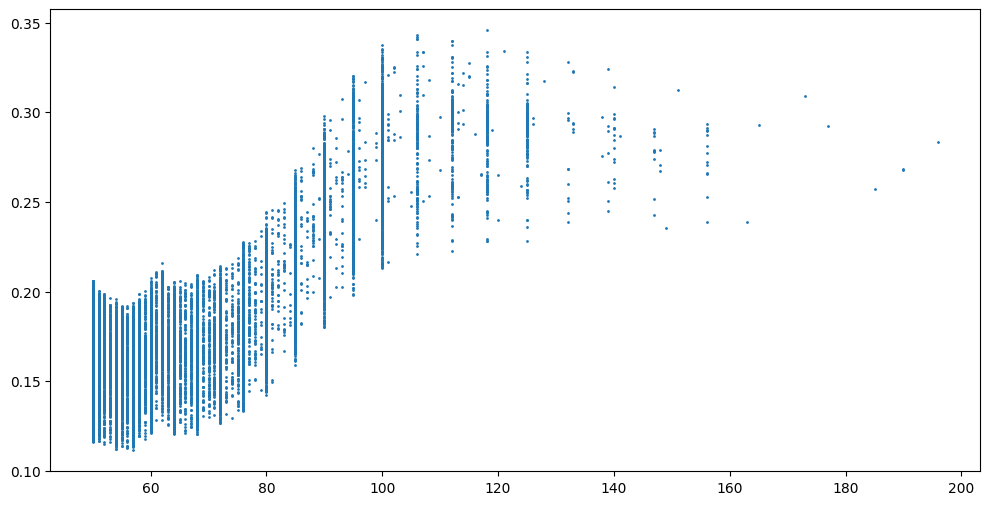

In [14]:
import matplotlib.pyplot as plt

trained_model.eval()
with torch.no_grad():
    att_scores = trained_model.get_att_scores(X_test, v_test)
att_scores_df = pd.DataFrame(
    att_scores.detach().numpy(), columns=cat_vars + cont_vars + ["cls"]
)

att_scores_df["explain_DrivAge"] = test["DrivAge"].values
att_scores_df["explain_BonusMalus"] = test["BonusMalus"].values
att_scores_df["explain_Region"] = test["Region"].values
att_scores_df["explain_Density"] = test["Density"].values


fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(att_scores_df["explain_BonusMalus"], att_scores_df["BonusMalus"], s=1)

### Driver age

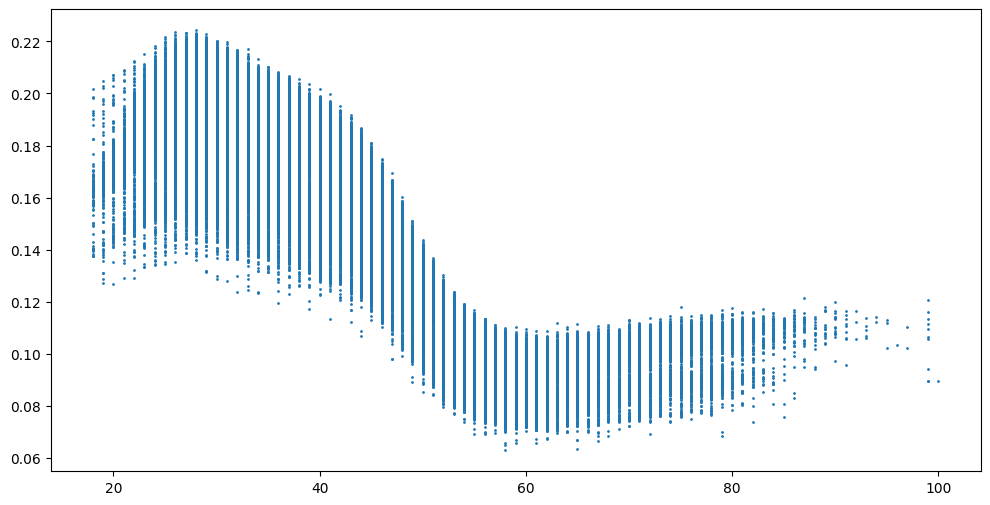

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(att_scores_df["explain_DrivAge"], att_scores_df["DrivAge"], s=1)

### Mean attention score

<Axes: >

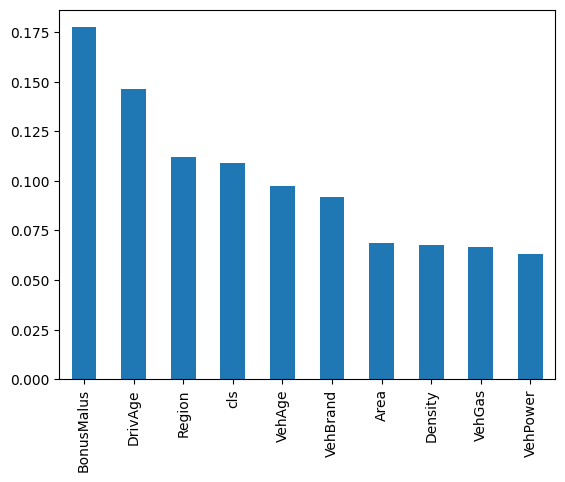

In [16]:
att_scores_df.iloc[:, :-4].mean(axis=0).sort_values(ascending=False).plot(kind="bar")

### Attention score of the CLS prior by observation

Mean attention score for the CLS prior in the ensemble model:
0.109092616


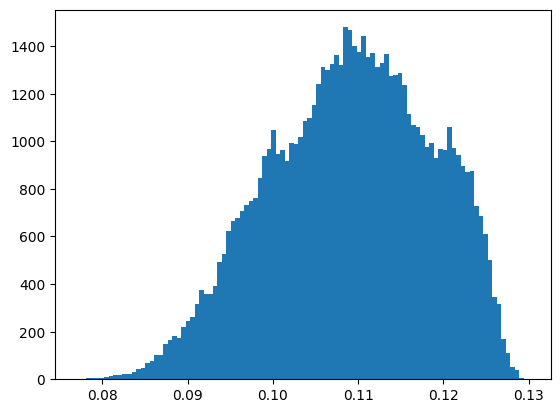

In [17]:
print("Mean attention score for the CLS prior in the ensemble model:")
print(att_scores_df["cls"].mean())
plt.hist(att_scores_df["cls"], bins=100);

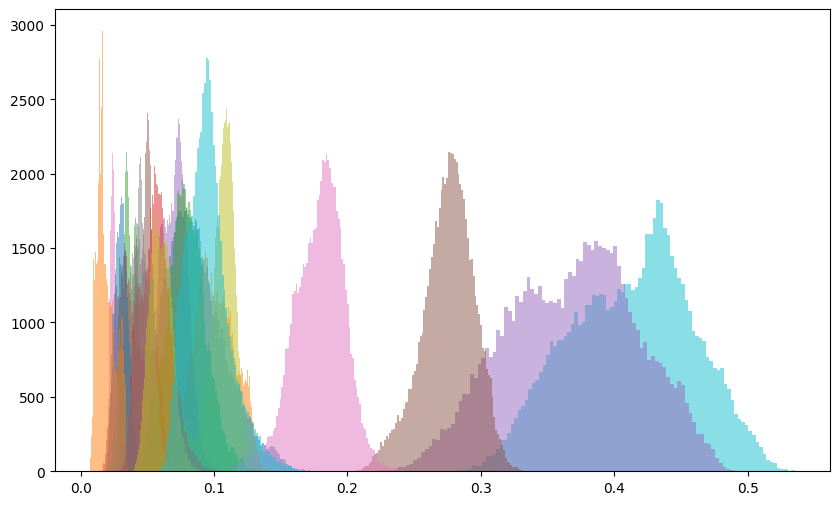

In [18]:
# plot attention scores histogram for CLS prior for each individual model
fig, ax = plt.subplots(figsize=(10, 6))
trained_model.eval()
with torch.no_grad():
    for model in trained_model.models:
        att_scores = model(X_test, v_test, return_att_scores=True)
        att_scores_df = pd.DataFrame(
            att_scores.detach().numpy(), columns=cat_vars + cont_vars + ["cls"]
        )
        ax.hist(att_scores_df["cls"], bins=100, alpha=0.5)

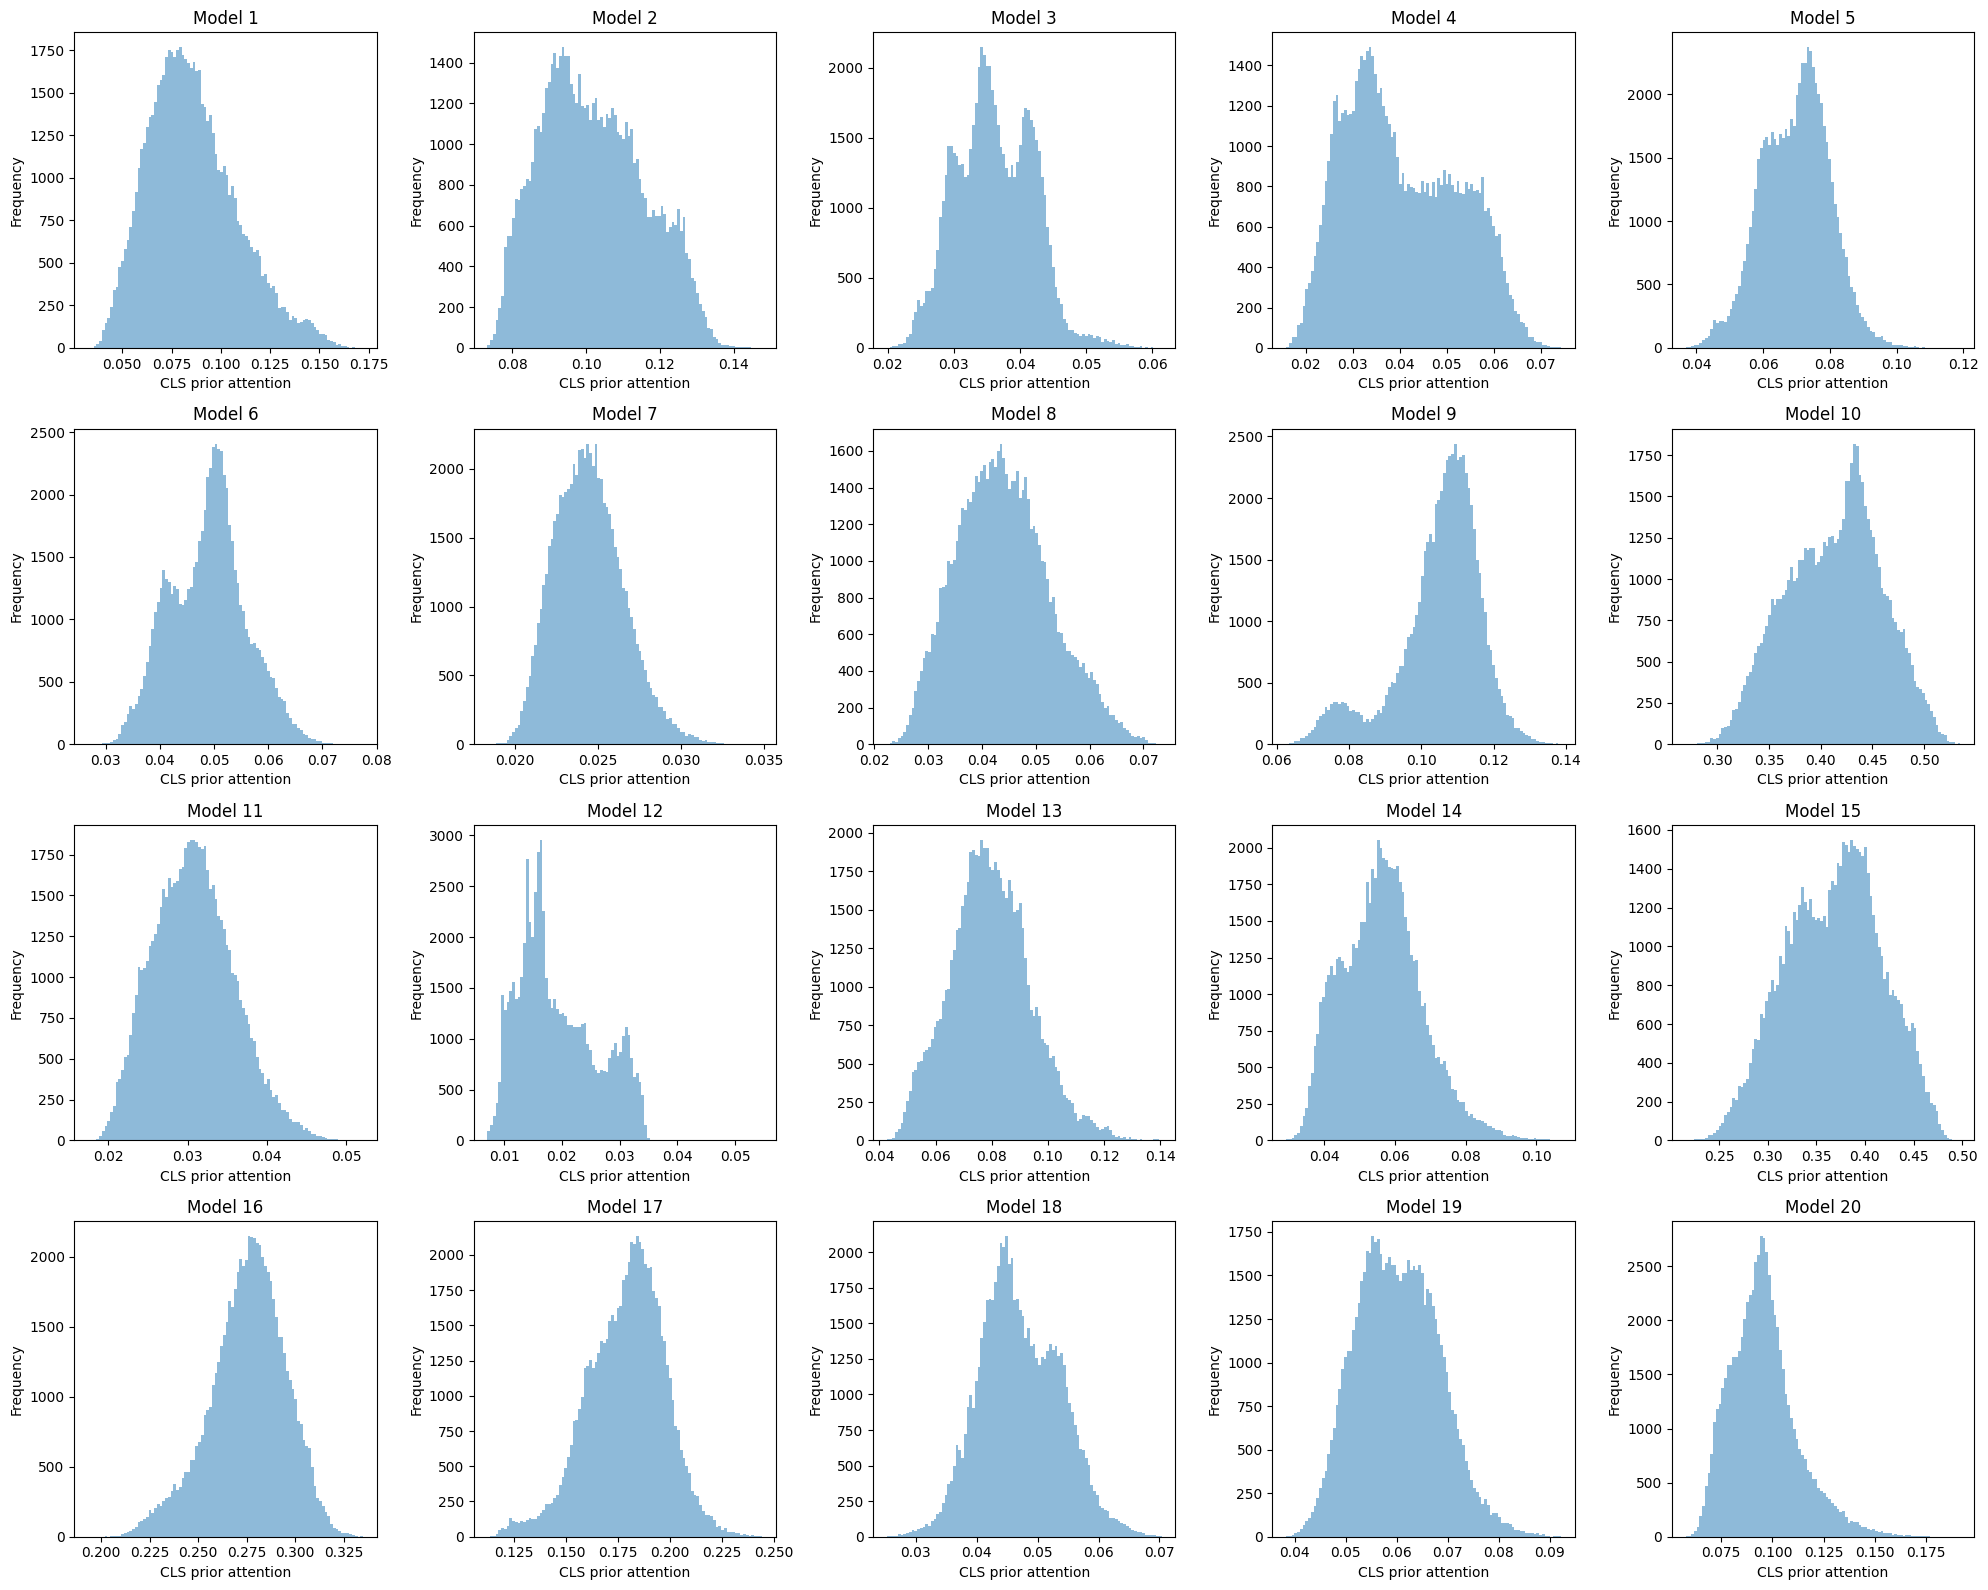

In [19]:
import math
import matplotlib.pyplot as plt

trained_model.eval()
n_models = len(trained_model.models)
n_cols = math.ceil(math.sqrt(n_models))
n_rows = math.ceil(n_models / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.ravel()

with torch.no_grad():
    for idx, model in enumerate(trained_model.models):
        att_scores = model(X_test, v_test, return_att_scores=True)
        att_scores_df = pd.DataFrame(
            att_scores.detach().numpy(), columns=cat_vars + cont_vars + ["cls"]
        )
        axes[idx].hist(att_scores_df["cls"], bins=100, alpha=0.5)
        axes[idx].set_title(f"Model {idx + 1}")
        axes[idx].set_xlabel("CLS prior attention")
        axes[idx].set_ylabel("Frequency")

for ax in axes[len(trained_model.models) :]:
    ax.axis("off")

plt.tight_layout()
